In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
path = "/content/drive/MyDrive/archive (2).zip"

In [ ]:
data = pd.read_csv(path)
print(data.shape)
data.head()

(5909, 4)


,pulse,body temperature,SpO2,Status
0,70,36.0,99,0
1,70,36.0,98,0
2,70,36.0,97,0
3,70,36.0,96,0
4,70,36.1,100,0


In [ ]:
data = data.dropna()
data = data.drop_duplicates()
print("Rows after cleaning:", len(data))

Rows after cleaning: 5909


In [ ]:
# Keep this order: pulse, temperature (Celsius), SpO2
X = data[["pulse", "body temperature", "SpO2"]].values
y = data["Status"].astype(int).values

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", len(X_train), "| Test:", len(X_test))

Train: 4727 | Test: 1182


In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
model = Sequential()

model.add(Input(shape=(3,)))
model.add(Dense(16, activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(3, activation='softmax'))

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = model.fit(X_train, y_train, epochs=15, validation_split=0.2)

Epoch 1/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9997 - loss: 0.0022 - val_accuracy: 1.0000 - val_loss: 0.0017
Epoch 2/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9997 - loss: 0.0022 - val_accuracy: 1.0000 - val_loss: 0.0017
Epoch 3/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9997 - loss: 0.0021 - val_accuracy: 1.0000 - val_loss: 0.0018
Epoch 4/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9997 - loss: 0.0021 - val_accuracy: 0.9989 - val_loss: 0.0018
Epoch 5/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9997 - loss: 0.0019 - val_accuracy: 0.9989 - val_loss: 0.0019
Epoch 6/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 0.0020 - val_accuracy: 0.9989 - val_loss: 0.0021
Epoch 7/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9997 - loss: 0.0019 - val_accuracy: 1.0000 - val_loss: 0.0018
Epoch 8/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9997 - loss: 0.0021 - val_accuracy: 1.

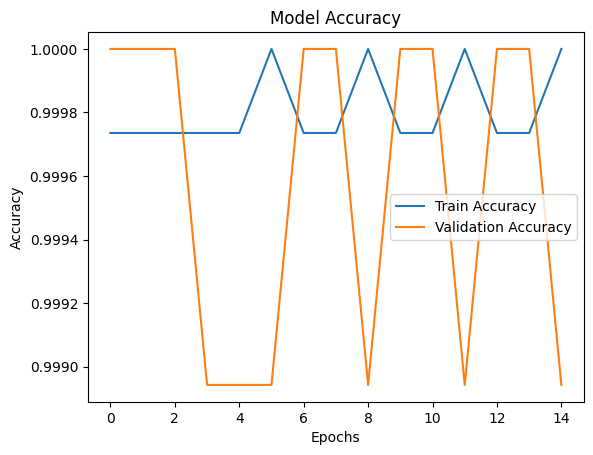

In [ ]:
plt.figure()
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.savefig("model_accuracy.png", dpi=150)
plt.show()

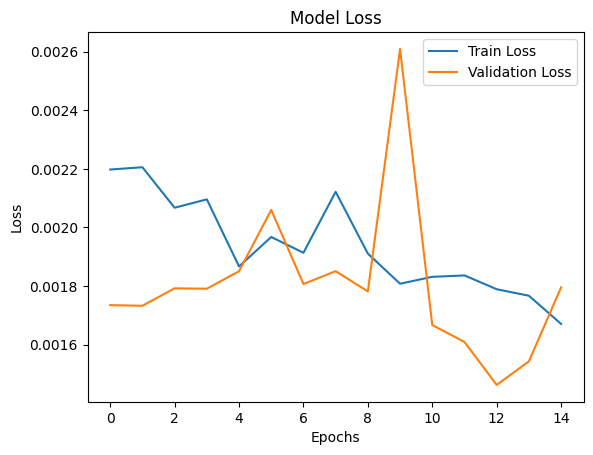

In [ ]:
plt.figure()
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig("model_loss.png", dpi=150)
plt.show()

In [ ]:
loss, acc = model.evaluate(X_test, y_test)
print("ANN Accuracy:", acc)

37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9983 - loss: 0.0033
ANN Accuracy: 0.9983079433441162


In [ ]:
y_pred = np.argmax(model.predict(X_test), axis=1)

37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


In [ ]:
print(confusion_matrix(y_test, y_pred))

[[200   0   0]
 [  0 480   0]
 [  0   2 500]]


In [ ]:
print(classification_report(y_test, y_pred, target_names=["Normal", "Low oxygen", "Very low oxygen"]))

                 precision    recall  f1-score   support

         Normal       1.00      1.00      1.00       200
     Low oxygen       1.00      1.00      1.00       480
Very low oxygen       1.00      1.00      1.00       502

       accuracy                           1.00      1182
      macro avg       1.00      1.00      1.00      1182
   weighted avg       1.00      1.00      1.00      1182



In [ ]:
names = ["Normal", "Low oxygen", "Very low oxygen"]

def check(spo2, pulse, temp_fahrenheit):
    temp_c = (temp_fahrenheit - 32) * 5 / 9
    values = scaler.transform([[pulse, temp_c, spo2]])
    result = model.predict(values, verbose=0)[0]
    print(f"SpO2={spo2}, Pulse={pulse}, Temp={temp_fahrenheit}F ->", names[int(np.argmax(result))])

In [ ]:
check(99, 72, 98.6)     # healthy
check(92, 95, 100.0)    # low oxygen
check(85, 110, 101.0)   # very low oxygen

SpO2=99, Pulse=72, Temp=98.6F -> Low oxygen
SpO2=92, Pulse=95, Temp=100.0F -> Very low oxygen
SpO2=85, Pulse=110, Temp=101.0F -> Very low oxygen


In [ ]:
model.save("oxygen_model.h5")

In [ ]:
import joblib
joblib.dump(scaler, "oxygen_scaler.pkl")

['oxygen_scaler.pkl']

In [ ]:
from google.colab import files
files.download("oxygen_model.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("oxygen_scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("model_accuracy.png")
files.download("model_loss.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>